# Imports

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt
from sklearn.model_selection import ParameterGrid
import uuid # for hashing

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [3]:
print(jax.local_device_count())

1


In [4]:
# Create default configuration storage object.
store = qnrl.store.HashStore()

In [5]:
# Show the number of configurations in hash store.
len(store)

164

# Playing around with QnRLv2

### Config

In [6]:
from dataclasses import dataclass
from qnrl.modules import SerializableModule
from functools import partial, reduce


def circuit_layer_circ(wires: list[int]):
    """Circular entanglement layer using `CZ`.

    Args:
        wires (list[int]): List of wires.
    """
    for w0, w1 in zip(wires, wires[1:]):
        qml.CZ(wires=[w0, w1])
    if len(wires) != 2:
        qml.CZ(wires=[wires[0], wires[-1]])

# def circuit_layer_enc(phi: jax.Array, wires: list[int]):
#     """Encoding layer using `RX`.

#     Args:
#         phi (jax.Array): Encoding parameters for the layer of shape `(num_wires,1)`.
#         wires (list[int]): _description_
#     """
#     for w in wires:
#         # ## Original
#         # qml.RX(phi=phi[w,0], wires=w)
#         ####
#         qml.Hadamard(wires=w)
#         qml.PhaseShift(phi=2*phi[w,0], wires=w)

def circuit_layer_enc(phi: jax.Array, wires: list[int], pauli: str = 'Z'):
    """Encoding layer using Pauli feature map.

    Args:
        phi (jax.Array): Encoding parameters for the layer of shape `(num_wires,1)`.
        wires (list[int]): _description_
    """
    
    for w in wires:
        qml.Hadamard(wires=w)
    
    match pauli.lower():
        case 'z':
            for w in wires:
                qml.PhaseShift(phi=phi[w,0], wires=w)
        case 'y':
            for w in wires:
                qml.SX(wires=w)
                qml.PhaseShift(phi=phi[w,0], wires=w)
                qml.adjoint(qml.SX(wires=w))
        case 'x':
            for w in wires:
                qml.Hadamard(wires=w)
                qml.PhaseShift(phi=phi[w,0], wires=w)
                qml.Hadamard(wires=w)

def circuit_layer_var(phi: jax.Array, wires: list[int]):
    """Variational layer `RZ * RY * RZ |psi>`.

    Args:
        phi (jax.Array): Variational parameters for the layer of shape `(num_wires,3)`.
        wires (list[int]): List of wires.
    """
    for w in wires:
        # ## Original
        # qml.RZ(phi=phi[w,0], wires=w)
        # qml.RY(phi=phi[w,1], wires=w)
        # qml.RZ(phi=phi[w,2], wires=w)
        #######
        qml.RY(phi=phi[w,0], wires=w)
        qml.RZ(phi=phi[w,1], wires=w)

def circuit_layer_reset(wires: list[int]):
    """Measure the given qubits to collapse their state, then reset to zero."""
    for w in wires:
        qml.measure(wires=w, reset=True)

def get_ops_for_returns_distribution(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_layers, d_returns, 3,)
    n_layers: int,
    wires: list[int],
    ):
    """Return-atom distribution unitary.
    
    Generates a return distribuion encoded on the given wires.
    
    The schema of this operation is:
        - `n_layers+1` Variational layers
        - `n_layers` Circular-entanglement layers
        - `n_layers` Input encoding layers
    """
    for l in range(n_layers):
        # ## Original
        # circuit_layer_var(phi=weights[l], wires=wires)
        # circuit_layer_circ(wires=wires)
        # circuit_layer_enc(phi=inputs[l], wires=wires)
        #######
        circuit_layer_enc(phi=inputs[l], wires=wires, pauli='Z')
        circuit_layer_var(phi=weights[l], wires=wires)
        circuit_layer_circ(wires=wires)
    circuit_layer_var(phi=weights[-1], wires=wires) # Final variational layer at the end.

def prepare_m_moment(
    m_moment: int,
    U_atoms: jax.Array,
    wires_returns: list[int],
    ):
    """Prepare m-th moment of the return distribuion encoded onto the given wires."""
    # Apply the (non-unitary) return-atom-value operation.
    # qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
    for _ in range(m_moment):
        qml.QubitUnitary(U_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.

def prepare_returns_probability_distribution(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    n_actions: int,
    n_layers: int,
    wires_actions: list[int],
    wires_returns: list[int],
    ):
    """Prepare return probability distribuion for every action."""
    ops = [
        qml.prod(get_ops_for_returns_distribution)(
            inputs=inputs,
            weights=weights[a],
            n_layers=n_layers,
            wires=wires_returns,
        )
        for a in range(n_actions)
    ]
    qml.Select(ops, control=wires_actions)

def circuit_action_dist(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    ):
    """Quantum circuit for estimating the action distribution via m-th moment of return distribuion followed by amplitude kickback trick with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
    )
    # Prepare the m-th moment of the returns distribution.
    prepare_m_moment(
        m_moment=m_moment,
        U_atoms=U_atoms,
        wires_returns=wiredict['returns'],
    )
    # Measure the return-atom qubits to collapse their state, then reset to zero.
    circuit_layer_reset(wires=wiredict['returns'])
    
    # Generate action distribuion via measurements across the action wires.
    return qml.probs(wires=wiredict['actions'])

def circuit_return_dist(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
    )
    
    # Generate weighted return distribuion via measurements across the return wires.
    return qml.probs(wires=wiredict['returns'])

def circuit_return_dist_shifted(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns, 2**d_returns)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
    )
    
    # Redistribute shifted return-atoms to align with original PMF atoms.
    qml.QubitUnitary(U_shift, wires=wiredict['returns'], unitary_check=False) # We know it's not unitary, so don't check.
    
    # Generate weighted return distribuion via measurements across the return wires.
    return qml.probs(wires=wiredict['returns'])

# TODO Input environment observation must pass through an ML layer to project the observations into a space ingestible for the quantum circuit.
def circuit_hermitian_loss(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
    )
    
    # Measure the expectation of the return-atom wires w.r.t. a given Hermitian operator.
    H = qml.Hermitian(rho, wires=wiredict['returns']) # Return-atom wires.
    # H = qml.Hermitian(rho, wires=wirelist) # All wires.
    return qml.expval(H)

def circuit_return_density_matrix(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    qml.Snapshot('after_action_prep', measurement=qml.density_matrix(wires=wirelist))
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
    )
    
    qml.Snapshot('after_return_prep', measurement=qml.density_matrix(wires=wirelist))
    
    # Density matrix for return-atom wires.
    return qml.density_matrix(wires=wiredict['returns'])
    # # Density matrix for all wires.
    # return qml.density_matrix(wires=wirelist)

def circuit_return_density_matrix_shifted(
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns, 2**d_returns)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Quantum circuit for generating the return distribution that is weighted via the probability amplitudes of the action space with respect to an input observation."""
    
    # Create wires.
    num_wires = d_actions + d_returns
    wirelist = list(range(num_wires)) # All wires.
    wiredict = { # Wires separated into blocks for each section.
        'actions': wirelist[:d_actions],
        'returns': wirelist[d_actions:]
    }
    
    # Weighted superposition of all actions.
    # Use `StatePrep` here because there may be fewer "active" actions than the total number of actions supported by the number of qubits in the action register. This ensures that all "inactive" actions have 0 amplitude.
    qml.StatePrep(probs_actions, wires=wiredict['actions'], normalize=True, pad_with=0)
    
    # Prepare returns probability distribution for every policy.
    prepare_returns_probability_distribution(
        inputs=inputs,
        weights=weights,
        n_actions=n_actions,
        n_layers=n_layers,
        wires_actions=wiredict['actions'],
        wires_returns=wiredict['returns'],
    )
    
    # Redistribute shifted return-atoms to align with original PMF atoms.
    qml.QubitUnitary(U_shift, wires=wiredict['returns'], unitary_check=False) # We know it's not unitary, so don't check.
    
    # Density matrix for return-atom wires.
    return qml.density_matrix(wires=wiredict['returns'])
    # # Density matrix for all wires.
    # return qml.density_matrix(wires=wirelist)

# @partial(nnx.vmap, in_axes=(0,None,None,None,0,None,0,None,None,None,None,None,None))
# 
@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'm_moment',
    'n_layers',
    'U_atoms',
])
def run_circuit_action_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    ):
    """Run `circuit_action_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_action_dist, device=device, interface="jax", diff_method=diff_method)
    # qnode_vmap = nnx.vmap(
    #     f=qnode,
    #     in_axes=(0, 0, *([None]*7)), # (inputs, probs_actions, weights, n_actions, d_actions, d_returns, m_moment, n_layers, U_atoms)
    #     out_axes=0, # inputs
    # )
    # return qnode_vmap(
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        m_moment=m_moment,
        n_layers=n_layers,
        U_atoms=U_atoms,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'm_moment',
    'n_layers',
    'U_atoms',
])
def batched_run_circuit_action_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    m_moment: int,
    n_layers: int,
    U_atoms: jax.Array,
    ):
    """Run `circuit_action_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_action_dist, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # m_moment
            None, # n_layers
            None, # U_atoms
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        m_moment,
        n_layers,
        U_atoms,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def run_circuit_return_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Run `circuit_return_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_dist, device=device, interface="jax", diff_method=diff_method)
    # qnode_vmap = nnx.vmap(
    #     f=qnode,
    #     in_axes=(0, 0, *([None]*5)), # (inputs, probs_actions, weights, n_actions, d_actions, d_returns, n_layers)
    #     out_axes=0, # inputs
    # )
    # return qnode_vmap(
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def batched_run_circuit_return_dist(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Run `circuit_return_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_dist, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def run_circuit_return_dist_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Run `circuit_return_dist` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_dist_shifted, device=device, interface="jax", diff_method=diff_method)
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        U_shift=U_shift,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def batched_run_circuit_return_dist_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Run `circuit_return_dist` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_dist_shifted, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            0, # U_shift
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        U_shift,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def run_circuit_hermitian_loss(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    ):
    """Run `circuit_hermitian_loss` on a single input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_hermitian_loss, device=device, interface="jax", diff_method=diff_method)
    # qnode_vmap = nnx.vmap(
    #     f=qnode,
    #     in_axes=(0, 0, *([None]*5), 0), # (inputs, probs_actions, weights, n_actions, d_actions, d_returns, n_layers, rho)
    #     out_axes=0, # inputs
    # )
    # return qnode_vmap(
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
        rho=rho,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def batched_run_circuit_hermitian_loss(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    rho: jax.Array, # Hermitian operator core.
    ):
    """Run `circuit_hermitian_loss` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_hermitian_loss, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            0, # rho
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
        rho,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def run_circuit_return_density_matrix(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Run `circuit_return_density_matrix` on a single of input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_density_matrix, device=device, interface="jax", diff_method=diff_method)
    # qnode_vmap = nnx.vmap(
    #     f=qnode,
    #     in_axes=(0, 0, *([None]*5)), # (inputs, probs_actions, weights, n_actions, d_actions, d_returns, n_layers)
    #     out_axes=0, # inputs
    # )
    # return qnode_vmap(
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def batched_run_circuit_return_density_matrix(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Run `circuit_return_density_matrix` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_density_matrix, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
    )


@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def run_circuit_return_density_matrix_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Run `circuit_return_density_matrix_shifted` on a single of input instance."""
    device = qml.device(name=device_name, shots=shots, seed=key)
    qnode = qml.QNode(func=circuit_return_density_matrix_shifted, device=device, interface="jax", diff_method=diff_method)
    # qnode_vmap = nnx.vmap(
    #     f=qnode,
    #     in_axes=(0, 0, *([None]*5)), # (inputs, probs_actions, weights, n_actions, d_actions, d_returns, n_layers)
    #     out_axes=0, # inputs
    # )
    # return qnode_vmap(
    return qnode(
        inputs=inputs,
        probs_actions=probs_actions,
        U_shift=U_shift,
        weights=weights,
        n_actions=n_actions,
        d_actions=d_actions,
        d_returns=d_returns,
        n_layers=n_layers,
    )

@partial(nnx.jit, static_argnames=[
    # Device and QNode parameters.
    'device_name', 'shots', 'diff_method',
    # Circuit parameters.
    'n_actions',
    'd_actions',
    'd_returns',
    'n_layers',
])
def batched_run_circuit_return_density_matrix_shifted(
    # All device and QNode parameters.
    key: jax.Array,
    device_name: str,
    shots: int | None,
    diff_method: str | None,
    # Circuit arguments.
    inputs: jax.Array, # (n_layers, d_returns, 1,)
    weights: jax.Array, # (n_actions, n_layers, d_returns, 3,)
    probs_actions: jax.Array,
    U_shift: jax.Array, # (2**d_returns,2**d_returns,)
    n_actions: int,
    d_actions: int,
    d_returns: int,
    n_layers: int,
    ):
    """Run `circuit_return_density_matrix_shifted` on a batch of input instances."""
    # Create vmap of core function.
    mapped_func = nnx.vmap(
        f=run_circuit_return_density_matrix_shifted, 
        in_axes=(
            0, # key
            None, # device_name
            None, # shots
            None, # diff_method
            0, # inputs
            None, # weights
            0, # probs_actions
            0, # U_shift
            None, # n_actions
            None, # d_actions
            None, # d_returns
            None, # n_layers
            ),
        )
    # Call mapped function with manually assigned positional arguments.
    return mapped_func(
        key,
        device_name,
        shots,
        diff_method,
        inputs,
        weights,
        probs_actions,
        U_shift,
        n_actions,
        d_actions,
        d_returns,
        n_layers,
    )



@dataclass(kw_only=True)
class QuantumNativeQNetworkSplit_v4(SerializableModule):
    """Split variant of quantum-native (distributional) Q-value network.
    
    Includes the following splits:
    1. Cascaded amplitude kickback circuit for action probability estimation to prevent memory explosion for high values of `n_reuploads` (with `diffmethod=None` and `shots>0`).
    2. Return distribuion generation and weighted return estimation circuit that ingests the action distribuion from #1 (with `diffmethod='backprop'` and `shots=None`).
    """
    din: int
    # n_policies: int
    # """Number of policies to optimize (will require `ceil(log2(n))` qubits)."""
    n_actions: int
    """Number of actions (will require `ceil(log2(n))` qubits)."""
    n_returns: int
    """Number of return atoms (will require `ceil(log2(n))` qubits)."""
    z_min: float
    z_max: float
    m_moment: int
    """m-th moment of the return atoms distribution (`E[Z^m]`)."""
    n_reuploads: int
    """n-th power of the expectation over the return atoms distribution (`E[Z]^n`)."""
    n_layers: int
    """Number of re-upload layers to use for the return-atom distribution unitary."""
    rngs_kwargs: dict[str, int]
    device_name: str = "default.qubit"
    diff_method: str | None = None
    shots: int = 100
    """Number of circuit shots used to compute action probability distribution."""
    
    def __post_init__(self):
        self.rngs: nnx.Rngs = nnx.Rngs(**self.rngs_kwargs)
        
        # Compute qubit count based on number of policies, actions, and return atoms.
        # self.d_policies = int(jnp.ceil(jnp.log2(self.n_policies))) # Qubit count for policies to optimize.
        self.d_actions = int(jnp.ceil(jnp.log2(self.n_actions))) # Qubit count for actions.
        self.d_returns = int(jnp.ceil(jnp.log2(self.n_returns))) # Qubit count for return atoms.
        
        # Collect indices of actions based on the total number of actions that can be represented by the number of qubits on the action register.
        self.all_action_idx = list(range(2**self.d_actions)) # All actions represented in the action qubit register.
        self.active_action_idx = list(range(self.n_actions)) # Indices of actions that are being used on the action qubit register.
        self.inactive_action_idx = list(set(self.all_action_idx) - set(self.active_action_idx)) # Indices of actions that are not being used on the action qubit register.
        
        # Collect indices of returns based on the total number of returns that can be represented by the number of qubits on the return register.
        self.all_return_idx = list(range(2**self.d_returns)) # All returns represented in the return qubit register.
        self.active_return_idx = list(range(self.n_returns)) # Indices of returns that are being used on the return qubit register.
        self.inactive_return_idx = list(set(self.all_return_idx) - set(self.active_return_idx)) # Indices of returns that are not being used on the return qubit register.
        
        # Create list of return atoms.
        # self.atoms = jnp.linspace(start=self.z_min, stop=self.z_max, num=self.n_returns)
        self.atoms = jnp.array(np.linspace(start=self.z_min, stop=self.z_max, num=self.n_returns))
        # Create non-linear trace non-increasing Kraus matrix of returns atoms.
        atoms_values = self.atoms
        atoms_values = atoms_values - atoms_values.min() # Start from zero.
        atoms_values = atoms_values / atoms_values.sum() # Normalize to probability distribution.
        atoms_values = jnp.sqrt(atoms_values * self.n_returns) # Ensure that L2-norm of quantum state amplitude will produce the atom probability (i.e., $|amp|^2 = prob$).
        atoms_values = atoms_values + 1e-5 # Small offset to ensure the lowest value is not zero.
        atoms_values = atoms_values / atoms_values.max() # Ensure maximum value is 1.
        # Pad with zeros if return atoms shape is not a power of 2.
        if self.n_returns != 2**self.d_returns:
            atoms_values = jnp.pad(atoms_values, (0,2**self.d_returns - self.n_returns), mode='constant')
        # Create quantum operator from the atom values.
        self.U_atoms = jnp.diag(atoms_values)
        
        # Weights for return-atom distribution generation.
        # Every action gets their own return-atom distribution unitary.
        # self.circ_weights_var_shape = (self.n_actions,self.n_layers,self.d_returns,3,) # Each qubit has (Rx, Ry, Rz).
        self.circ_weights_var_shape = (self.n_actions,self.n_layers,self.d_returns,2,) # Each qubit has (Rx, Ry, Rz).
        self.circ_weights_var = nnx.Param(jax.random.uniform(self.rngs.params(), shape=self.circ_weights_var_shape, minval=0, maxval=jnp.pi))
        #
        self.circ_weights_enc_obs_shape = (self.n_layers,self.d_returns,1,) # Encode using (Rx,).
        self.circ_weights_enc_obs = nnx.Param(jnp.ones(shape=self.circ_weights_enc_obs_shape))
        
        # Inputs to circuit will be encoded onto the return-atom wires.
        self.circ_observation_shape_in = self.din # Input dimension of the observations.
        self.circ_observation_shape_out = (self.d_returns,1,) # Each qubit has (Rx,).
        self.layer_project_input = nnx.Linear(in_features=self.circ_observation_shape_in, out_features=reduce(lambda x,y: x*y, self.circ_observation_shape_out), rngs=self.rngs)
        
        assert self.shots is not None and self.shots > 0, f"number if shots is invalid: {self.shots}"
    
    @nnx.jit
    def __call__(self, x): # (batch,din,)
        return self.call_gen_action_dist(x) # Generation action distribution.
        # # Project input into shape that is compatible with the quantum circuit.
        # x = self.layer_project_input(x)
        # # Input must be batched for input into the circuit.
        # x = jnp.reshape(x, (-1, *self.circ_inputs_shape,)) # (batch,d_returns,1,)
        # # Prepare the n-th power of the m-th moment of the returns distribution.
        # key = self.rngs.default() # Generate new random key for circuit measurement.
        # probs_actions = jnp.ones(shape=(x.shape[0], self.n_actions,), dtype='float64')
        # for _ in range(self.n_reuploads):
        #     # jax.debug.print("[QuantumNativeQNetworkCascade] Upload {n}: start, {probs_actions}", n=n, probs_actions=probs_actions)
        #     # Run quantum circuit.
        #     key, subkey = jax.random.split(key=key)
        #     probs_actions = self.run_circuit( # (batch,2**d_actions,)
        #         # All device and QNode parameters.
        #         key=subkey,
        #         device_name=self.device_name,
        #         shots=self.shots,
        #         diff_method=self.diff_method,
        #         # Circuit arguments.
        #         inputs=x,
        #         probs_actions=probs_actions,
        #         weights=self.circ_weights,
        #         # weights=self.circ_weights[n],
        #         n_actions=self.n_actions,
        #         d_actions=self.d_actions,
        #         d_returns=self.d_returns,
        #         m_moment=self.m_moment,
        #         n_layers=self.n_layers,
        #         U_atoms=self.U_atoms,
        #     )
        #     # Filter circuit output based on number of "active" actions.
        #     # If desired number of actions is not a multiple of 2, then filter out the excess actions on the qubit register (i.e., more actions can be represented on the register and we don't care about them).
        #     probs_actions = probs_actions[:,jnp.array(self.active_action_idx, dtype=int)] # (batch,n_actions,)
        #     # Ensure probabilities are normalized after the filter.
        #     probs_actions = probs_actions / probs_actions.sum(axis=-1, keepdims=True)
        #     # jax.debug.print("[QuantumNativeQNetworkCascade] Upload {n}: done, {probs_actions}", n=n, probs_actions=probs_actions)
        # return probs_actions
    
    @nnx.jit
    def project_observations(self, observations: jax.Array): # (batch,din,)
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.layer_project_input(observations) # (batch * d_returns * 1,)
        # Reshape into batched vector with predefined shape for observation data as input to the circuit.
        observation_proj_batched = jnp.reshape(observation_proj_batched, (-1, *self.circ_observation_shape_out,)) # (batch, d_returns, 1,)
        #
        # Transform projected observations into encoding angles.
        # Einsum dimension labels:
        #   b = batch
        #   l = layer
        #   q = qubit
        #   f = feature
        angles_enc = jnp.einsum("lqf,bqf->blqf", self.circ_weights_enc_obs, observation_proj_batched) # (batch, n_layers, d_returns, 1,)
        # Squash encoding angles.
        angles_enc = 2. * jnp.arctan(angles_enc) # [-pi, pi]
        #
        return angles_enc
    
    
    # @nnx.jit
    # def call_gen_action_dist(self, x): # (batch,din,)
    @nnx.jit(static_argnames=['n_reuploads'])
    def call_gen_action_dist(self, x, n_reuploads: int | None = None): # (batch,din,)
        """Generate action distribuion from input observation."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Prepare the n-th power of the m-th moment of the returns distribution.
        key = self.rngs.default() # Generate new random key for circuit measurement.
        probs_actions = jnp.ones(shape=(batch_size, self.n_actions,), dtype='float64')
        if n_reuploads is None:
            n_reuploads = self.n_reuploads
        # for _ in range(self.n_reuploads):
        # Create a batch of keys.
        # subkeys = jax.random.split(key=key, num=batch_size)
        subkeys = [key]
        for _ in range(n_reuploads):
            # jax.debug.print("[QuantumNativeQNetworkCascade] Upload {n}: start, {probs_actions}", n=n, probs_actions=probs_actions)
            # Run quantum circuit.
            # key, subkey = jax.random.split(key=key)
            # probs_actions = self.run_circuit_action_dist( # (batch,2**d_actions,)
            #     # All device and QNode parameters.
            #     # key=subkey,
            #     key=subkeys,
            #     device_name=self.device_name,
            #     # device_name="default.mixed",
            #     # shots=self.shots,
            #     # diff_method=self.diff_method,
            #     shots=100, diff_method=None, # Shots with no diffmethod ensures that memory doesn't explore with reset operations.
            #     # Circuit arguments.
            #     inputs=x,
            #     probs_actions=probs_actions,
            #     weights=self.circ_weights,
            #     n_actions=self.n_actions,
            #     d_actions=self.d_actions,
            #     d_returns=self.d_returns,
            #     m_moment=self.m_moment,
            #     n_layers=self.n_layers,
            #     U_atoms=self.U_atoms,
            # )
            # Create a batch of keys for the current reupload.
            subkeys = jax.random.split(key=subkeys[0], num=batch_size)
            # Run the circuit on batched input.
            probs_actions = batched_run_circuit_action_dist( # (batch,2**d_actions,)
                # All device and QNode parameters.
                key=subkeys,
                # 
                # device_name=self.device_name,
                # shots=self.shots,
                # diff_method=self.diff_method,
                # 
                device_name="default.qubit",
                # device_name="default.mixed",
                shots=self.shots,
                diff_method=None,
                # 
                # shots=100, diff_method=None, # Shots with no diffmethod ensures that memory doesn't explore with reset operations.
                # shots=1000, diff_method=None, # Shots with no diffmethod ensures that memory doesn't explore with reset operations.
                # Circuit arguments.
                inputs=observation_proj_batched,
                probs_actions=probs_actions,
                weights=self.circ_weights_var,
                n_actions=self.n_actions,
                d_actions=self.d_actions,
                d_returns=self.d_returns,
                m_moment=self.m_moment,
                n_layers=self.n_layers,
                U_atoms=self.U_atoms,
            )
            # jax.debug.print("a = {}", a)
            # Filter circuit output based on number of "active" actions.
            # If desired number of actions is not a multiple of 2, then filter out the excess actions on the qubit register (i.e., more actions can be represented on the register and we don't care about them).
            probs_actions = probs_actions[:,jnp.array(self.active_action_idx, dtype=int)] # (batch,n_actions,)
            # Ensure probabilities are normalized after the filter.
            probs_actions = probs_actions / probs_actions.sum(axis=-1, keepdims=True)
            # jax.debug.print("[QuantumNativeQNetworkCascade] Upload {n}: done, {probs_actions}", n=n, probs_actions=probs_actions)
        return probs_actions
    
    @nnx.jit
    def call_gen_return_dist(self, x): # (batch,din,)
        """Generate return distribuion from input observation."""
        
        # TODO freeze weights for action distribution generation?
        # probs_actions = self.call_gen_action_dist(x)
        probs_actions = self.call_gen_action_dist(jax.lax.stop_gradient(x))
        # # Stop gradient.
        # probs_actions = jax.lax.stop_gradient(probs_actions)
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()
        
        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        probs_returns = batched_run_circuit_return_dist( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            device_name=self.device_name,
            # shots=self.shots, diff_method=self.diff_method,
            shots=None, diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
        )
        # Filter circuit output based on number of "active" returns.
        # If desired number of returns is not a multiple of 2, then filter out the excess returns on the qubit register (i.e., more returns can be represented on the register and we don't care about them).
        probs_returns = probs_returns[:,jnp.array(self.active_return_idx, dtype=int)] # (batch,n_returns,)
        # Ensure probabilities are normalized after the filter.
        probs_returns = probs_returns / probs_returns.sum(axis=-1, keepdims=True)
        return probs_returns
    
    @nnx.jit
    def call_gen_return_dist_NEW(self, x, probs_actions): # (batch,din,)
        """Generate return distribuion from input observation."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        probs_returns = batched_run_circuit_return_dist( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            #
            # device_name=self.device_name,
            # shots=None, diff_method='backprop',
            # 
            # device_name='default.mixed',
            device_name='default.qubit',
            shots=None, diff_method='backprop',
            #
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
        )
        # Filter circuit output based on number of "active" returns.
        # If desired number of returns is not a multiple of 2, then filter out the excess returns on the qubit register (i.e., more returns can be represented on the register and we don't care about them).
        probs_returns = probs_returns[:,jnp.array(self.active_return_idx, dtype=int)] # (batch,n_returns,)
        # Ensure probabilities are normalized after the filter.
        probs_returns = probs_returns / probs_returns.sum(axis=-1, keepdims=True)
        return probs_returns
    
    @nnx.jit
    def call_gen_return_dist_shifted(self, x, probs_actions, U_shift): # (batch,din,)
        """Generate shifted return distribuion from input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        probs_returns = batched_run_circuit_return_dist_shifted( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            #
            # device_name=self.device_name,
            # shots=None, diff_method='backprop',
            # 
            device_name='default.mixed',
            shots=None, diff_method='backprop',
            #
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            U_shift=U_shift,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
        )
        # Filter circuit output based on number of "active" returns.
        # If desired number of returns is not a multiple of 2, then filter out the excess returns on the qubit register (i.e., more returns can be represented on the register and we don't care about them).
        probs_returns = probs_returns[:,jnp.array(self.active_return_idx, dtype=int)] # (batch,n_returns,)
        # Ensure probabilities are normalized after the filter.
        probs_returns = probs_returns / probs_returns.sum(axis=-1, keepdims=True)
        return probs_returns
    
    
    @nnx.jit
    def call_hermitian_loss(self, x, probs_actions, rho): # (batch,din,)
        """Compute Hermitian loss across the return-atom qubits with respect to an input density matrix rho."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        loss = batched_run_circuit_hermitian_loss( # (batch,2**d_returns,)
            # All device and QNode parameters.
            key=subkeys,
            # device_name=self.device_name,
            device_name="default.mixed", # Use mixed state simulation for density matrix.
            # shots=self.shots, diff_method=self.diff_method,
            shots=None, diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
            rho=rho,
        )
        return loss
    
    @nnx.jit
    def call_return_density_matrix(self, x, probs_actions): # (batch,din,)
        """Generate the density matrix across the return-atom qubits according to an input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        rho = batched_run_circuit_return_density_matrix( # (batch,2**d_returns,2**d_returns)
            # All device and QNode parameters.
            key=subkeys,
            # device_name=self.device_name,
            device_name="default.mixed", # Use mixed state simulation for density matrix.
            # shots=self.shots, diff_method=self.diff_method,
            shots=None, diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
        )
        return rho
    
    @nnx.jit
    def call_return_density_matrix_shifted(self, x, probs_actions, U_shift): # (batch,din,)
        """Generate the shifted density matrix across the return-atom qubits according to an input observation and action probability distribution."""
        
        # Track the batch size.
        batch_size = x.shape[0] if len(x.shape) > 1 else 1 if len(x.shape) > 1 else 1
        
        # Project input observation into shape that is compatible with the quantum circuit.
        observation_proj_batched = self.project_observations(x) # (batch, n_layers, d_returns, 1,)
        
        # Generate new random key for circuit measurement.
        key = self.rngs.default()

        # Create a batch of keys.
        subkeys = jax.random.split(key=key, num=batch_size)
        
        # Run the circuit.
        rho = batched_run_circuit_return_density_matrix_shifted( # (batch,2**d_returns,2**d_returns)
            # All device and QNode parameters.
            key=subkeys,
            # device_name=self.device_name,
            device_name="default.mixed", # Use mixed state simulation for density matrix.
            # shots=self.shots, diff_method=self.diff_method,
            shots=None, diff_method='backprop',
            # Circuit arguments.
            inputs=observation_proj_batched,
            probs_actions=probs_actions,
            U_shift=U_shift,
            weights=self.circ_weights_var,
            n_actions=self.n_actions,
            d_actions=self.d_actions,
            d_returns=self.d_returns,
            n_layers=self.n_layers,
        )
        return rho

In [ ]:
# # Load config from file.
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-13.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-12.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-11.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-10.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-9.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-8.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-7.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-6.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-5.py")
# # cfg_path = Path("./experiments/qnrl_CartPole-v1_config-0.py")
# module = qnrl.tools.load_python_module_from_filepath(cfg_path)
# config = module.config

from qnrl.algorithms.qnrl_v2 import QnRL_v2
from qnrl.optimizer import *
from qnrl.gym import *
from qnrl.modules import *


# CartPole-v1
din = 4
n_actions = 2

# n_returns = 101
# n_returns = 2**7 # 128
n_returns = 2**5

z_min = -100
z_max = 100
m_moment = 1
n_reuploads = 2
# n_reuploads = 4
# n_reuploads = 1
n_layers = 5
# n_layers = 1
# diff_method="backprop"
# shots=None
diff_method=None
# shots=100
# shots=500
shots=1000
seed = 0
# seed = 42

# Experiment configuration.
config = QnRL_v2(
    buffer_size=10_000,
    seed=seed,
    batch_size=128,
    # total_timesteps=500_000,
    total_timesteps=20_000,
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5,
    #
    env=ScaleObservation(
        env=EnvConfig(env_id="CartPole-v1"),
        scale=[2.4, 2.5, 0.21, 2.5],
    ),
    # model=QuantumNativeQNetworkSplit_v3(
    model=QuantumNativeQNetworkSplit_v4(
        din=din,
        n_actions=n_actions,
        n_returns=n_returns,
        z_min=z_min,
        z_max=z_max,
        m_moment=m_moment,
        n_reuploads=n_reuploads,
        n_layers=n_layers,
        diff_method=diff_method,
        shots=shots,
        rngs_kwargs=dict(default=seed),
    ),
    # optimizer=Adam(learning_rate=1.0e-4),
    optimizer=Adam(learning_rate=1.0e-3),
    # optimizer=Adam(learning_rate=1.0e-2),
    # optimizer=Adam(learning_rate=25e-5),
    # optimizer=Partition(
    #     transforms={
    #         # 'key_circuit_weights': Adam(learning_rate=1.0e-2),
    #         'key_circuit_weights': Adam(learning_rate=1.0e-3),
    #         # 'key_layer_project_input': Adam(learning_rate=1.0e-3),
    #         # 'key_layer_project_input': Adam(learning_rate=1.0e-1),
    #         'key_layer_project_input': Adam(learning_rate=1.0e-2),
    #     },
    #     pytree={
    #         'circ_weights': 'key_circuit_weights',
    #         'layer_project_input': {
    #             'bias': 'key_layer_project_input',
    #             'kernel': 'key_layer_project_input',
    #         },
    #     },
    # ),
    # policy_type='stochastic',
    # policy_type='phased_stochastic_greedy',
    policy_type='greedy',
    # target_type='stochastic',
    target_type='greedy',
    # target_type='uniform',
)

if store.exists(config):
    print(f"Already exists in store")
    cfg_hash, cfg_str = store.hash(config)
    
else:
    print(f"New hash")
    # Generate hash for the current config and store it for later retrieval.
    cfg_hash, cfg_str = store.store_obj(config)

print(f"Config String: {cfg_str}")
print(f"Config Hash: {cfg_hash}")

Already exists in store
Config String: {"type": "qnrl_v2", "env": {"env": {"env_id": "CartPole-v1", "render_mode": null, "max_episode_steps": null, "extra_args": null}, "scale": [2.4, 2.5, 0.21, 2.5]}, "metric_manager": null, "checkpoint": null, "model": {"type": "QuantumNativeQNetworkSplit_v4", "din": 4, "n_actions": 2, "n_returns": 32, "z_min": -100, "z_max": 100, "m_moment": 1, "n_reuploads": 2, "n_layers": 5, "rngs_kwargs": {"default": 0}, "device_name": "default.qubit", "diff_method": null, "shots": 1000}, "optimizer": {"type": "adam", "learning_rate": 0.01, "b1": 0.9, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "policy_type": "greedy", "target_type": "greedy", "buffer_size": 10000, "seed": 0, "batch_size": 128, "total_timesteps": 20000, "learning_starts": 10000, "policy_update_frequency": 10, "target_update_frequency": 500, "gamma": 0.99, "tau": 1.0, "eps_start": 1, "eps_end": 0.05, "eps_exploration": 0.5}
Config Hash: 69729cc3-8dd2-581f-91fc

In [8]:
# Tally the model parameters.
qnrl.tools.get_model_total_parameter_count(config.model)

150

In [9]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'circ_weights_enc_obs': Param( # 25 (200 B)
    value=Array([[[1.],
            [1.],
            [1.],
            [1.],
            [1.]],
    
           [[1.],
            [1.],
            [1.],
            [1.],
            [1.]],
    
           [[1.],
            [1.],
            [1.],
            [1.],
            [1.]],
    
           [[1.],
            [1.],
            [1.],
            [1.],
            [1.]],
    
           [[1.],
            [1.],
            [1.],
            [1.],
            [1.]]], dtype=float64)
  ),
  'circ_weights_var': Param( # 100 (800 B)
    value=Array([[[[3.04718150e+00, 9.90173016e-01],
             [2.07689556e+00, 3.11453352e+00],
             [8.87567600e-01, 1.11680092e+00],
             [1.65014390e+00, 1.01350402e+00],
             [1.84341560e-01, 1.93242849e+00]],
    
            [[2.99935919e+00, 2.63506254e+00],
             [2.49077317e+00, 5.59606386e-01],
             [1.17210210e+00, 2.41652854e+00],
             

In [10]:
# Create environment instance for later.
env = config.env.make()

In [11]:
# Generate a batch of environment observations.
# observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
# 
obs = env.reset()[0]
# for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
observations = jnp.array([obs for _ in range(config.batch_size)])

In [12]:
o = jnp.array([[-0.00941539, 0.0007998, 0.04141781, -0.00324702]])
config.model.call_gen_return_dist_NEW(o, jnp.array([[1,0]]))

Array([[0.00040028, 0.04071724, 0.03593529, 0.01985739, 0.09751174,
        0.08905649, 0.02439252, 0.04185593, 0.02354584, 0.09877598,
        0.03857195, 0.04701471, 0.01345127, 0.00817578, 0.06029593,
        0.0001011 , 0.01556985, 0.02266081, 0.02904803, 0.03634771,
        0.02098962, 0.08016003, 0.09369721, 0.00936845, 0.00767496,
        0.00458619, 0.00405231, 0.00836359, 0.00679269, 0.00031029,
        0.00229125, 0.01842757]], dtype=float64)

In [13]:
action_pmf = config.model.call_gen_action_dist(observations)
config.model.call_gen_return_dist_NEW(observations, action_pmf)

Array([[0.00079721, 0.01874854, 0.02573059, ..., 0.02987992, 0.01457302,
        0.11208545],
       [0.00079227, 0.01858621, 0.02567914, ..., 0.03012332, 0.01464613,
        0.11294222],
       [0.00078981, 0.0185052 , 0.02565347, ..., 0.03024478, 0.01468262,
        0.11336977],
       ...,
       [0.00080151, 0.01888993, 0.0257754 , ..., 0.0296679 , 0.01450934,
        0.11133915],
       [0.00080097, 0.0188721 , 0.02576974, ..., 0.02969464, 0.01451737,
        0.11143327],
       [0.00080044, 0.01885459, 0.0257642 , ..., 0.02972089, 0.01452526,
        0.11152568]], dtype=float64)

In [14]:
def inspect_density_matrix(env, model):
    """Display the model return-atom density matrix for a random environment observation."""
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    obs = env.reset()[0]
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    observations = jnp.array([obs])

    # Check density matrix and action PMF before training.
    # obs, _ = env.reset()
    # action_pmf = config.model.call_gen_action_dist(obs)
    # action_pmf = 1./config.model.n_actions * jnp.ones(shape=(observations.shape[0],config.model.n_actions))
    # action_pmf = jnp.ones(shape=(observations.shape[0],config.model.n_actions))
    # 
    action_pmf = model.call_gen_action_dist(observations)
    # action_pmf = jnp.zeros((observations.shape[0], model.n_actions)).at[:,0].set(1)
    # action_pmf = jnp.zeros((observations.shape[0], model.n_actions)).at[:,1].set(1)
    # action_pmf

    rho = model.call_return_density_matrix(observations, action_pmf)

    # print(f"{action_pmf = }")
    # print(f"{action_pmf[0] = }")
    # print(f"{rho[0] = }")
    # print(f"{rho[0].conj().T = }")
    # print(f"{jax.vmap(jnp.trace)(rho)[0] = }")
    # print(f"{jax.vmap(lambda p: jnp.trace(p.conj().T))(rho)[0] = }")
    # print(f"{jax.vmap(lambda p: jnp.trace(p @ p.conj().T))(rho)[0] = }")
    # print(jnp.isclose(jax.vmap(jnp.trace)(rho)[0], jax.vmap(lambda p: jnp.trace(p @ p.conj().T))(rho)[0], ))

    # print(f"{qnrl.tools.is_unitary(rho[0]) = }")
    # print(f"{qnrl.tools.is_hermitian(rho[0]) = }")
    # print(f"{qnrl.tools.is_pure(rho[0]) = }")

    # jnp.all(jnp.isclose(rho[0], rho[0].conj().T))

    nnx.display(action_pmf[0])
    nnx.display(jnp.array([jnp.real(rho[0]), jnp.imag(rho[0])]))
    nnx.display(jnp.abs(rho[0]))

In [15]:
# Inspect density matrices before training.
inspect_density_matrix(config.env.make(), config.model)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_4834/4105323551.py:41: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()




In [16]:

key = jax.random.PRNGKey(0)
device_name = 'default.mixed'
shots = None
diff_method = "backprop"

model = config.model
inputs = jax.random.normal(key=key, shape=(1, model.circ_observation_shape_in))
weights = model.circ_weights_var
probs_actions = jnp.ones(shape=(model.n_actions,))
n_actions = model.n_actions
d_actions = model.d_actions
d_returns = model.d_returns
n_layers = model.n_layers

device = qml.device(name=device_name, shots=shots, seed=key)
qnode = qml.QNode(func=circuit_return_dist, device=device, interface="jax", diff_method=diff_method)
# print(qml.draw(qnode, level='device')(
#     inputs=inputs,
#     # probs_actions=probs_actions,
#     probs_actions=jnp.array([1/np.sqrt(2), 1/np.sqrt(2)]),
#     weights=weights,
#     n_actions=n_actions,
#     d_actions=d_actions,
#     d_returns=d_returns,
#     n_layers=n_layers,
# ))

observation_proj = model.project_observations(inputs)

fig, ax = qml.draw_mpl(qnode, level='device', style='sketch', decimals=2)(
    inputs=observation_proj,
    # probs_actions=probs_actions,
    probs_actions=jnp.array([1/np.sqrt(2), 1/np.sqrt(2)]),
    weights=weights,
    n_actions=n_actions,
    d_actions=d_actions,
    d_returns=d_returns,
    n_layers=n_layers,
)

fig.show()

### Train

In [17]:
train = True
save_metrics = True
metric_filepath = Path(f"./metrics/{cfg_hash}.json")

In [18]:
if metric_filepath.exists() and not train:
    print(f"Loading existing train results")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    history_list = qnrl.tools.load_train_results(metric_filepath)
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
else:
    print(f"Training")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    
    history_list = config.train()
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    # Preserve training results.
    if save_metrics:
        qnrl.tools.save_train_results(metric_filepath, history_list)

Training
Store: hashstore.json
Hash: 69729cc3-8dd2-581f-91fc-bed66f4356fb
History: metrics/69729cc3-8dd2-581f-91fc-bed66f4356fb.json


  0%|          | 0/20000 [00:00<?, ?step/s]/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
100%|██████████| 20000/20000 [27:06<00:00, 12.30step/s, episode_step=2e+4, episode_reward=17, episode_length=17, episode_time=1.22, episode_utcisotime=2025-09-23T00:47:13.972320+00:00, loss_step=2e+4, loss=0.01913842486298367]     


Text(0, 0.5, 'episode_reward')

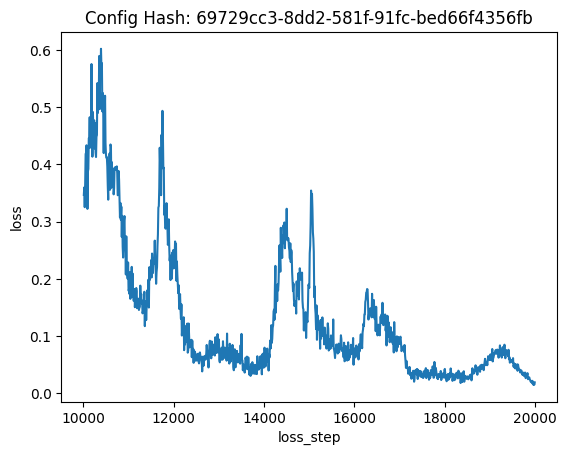

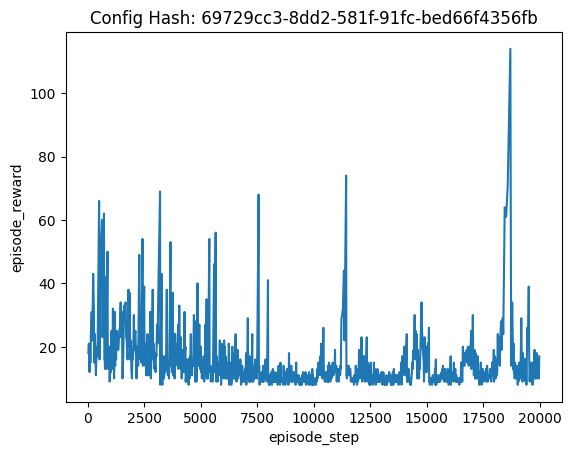

In [19]:
import matplotlib.pyplot as plt

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['loss_step'], history_dict['loss'])
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['episode_step'], history_dict['episode_reward'])
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

./figures/69729cc3-8dd2-581f-91fc-bed66f4356fb.pdf


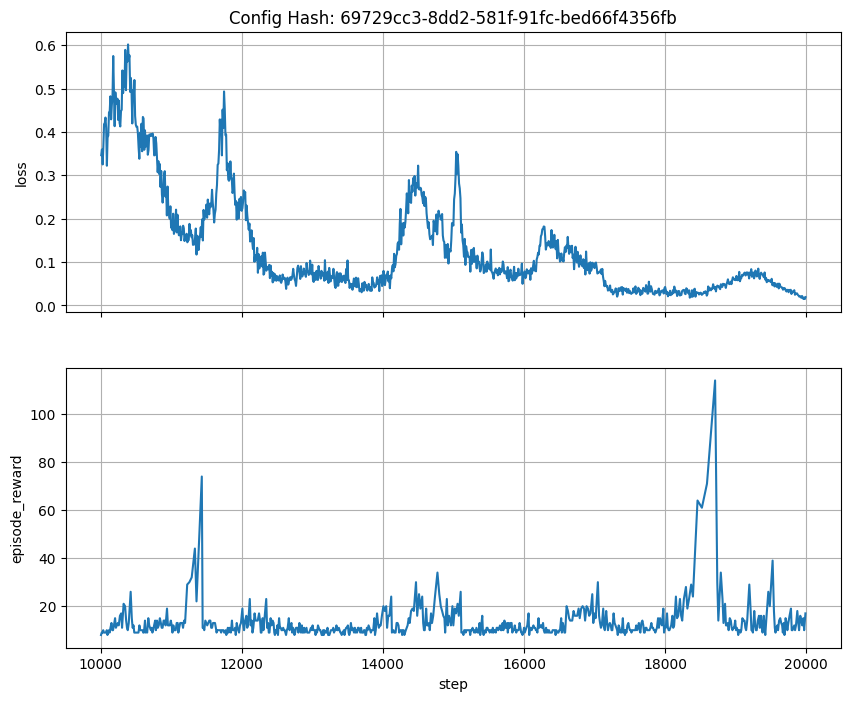

In [20]:
# Plot loss and episode reward on the same plot.

history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

fig, axs = plt.subplots(2,1, sharex=True, figsize=(10,8))
axs = axs.squeeze()

axs[0].set_title(f"Config Hash: {cfg_hash}")
plt.xlabel('step')

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['loss_step']) >= config.learning_starts
history_dict['loss_step'] = np.array(history_dict['loss_step'])[idx]
history_dict['loss'] = np.array(history_dict['loss'])[idx]

# Only consider data points that are after learning starts (because this is where loss starts accumulating).
idx = np.array(history_dict['episode_step']) >= config.learning_starts
history_dict['episode_step'] = np.array(history_dict['episode_step'])[idx]
history_dict['episode_reward'] = np.array(history_dict['episode_reward'])[idx]

axs[0].plot(history_dict['loss_step'], history_dict['loss'])
axs[0].set_ylabel('loss')
axs[0].grid() # Turn on a grid.

axs[1].plot(history_dict['episode_step'], history_dict['episode_reward'])
axs[1].set_ylabel('episode_reward')
axs[1].grid() # Turn on a grid.

# Save the figure file.
figfile = f"./figures/{cfg_hash}.pdf"
fig.savefig(figfile)
print(figfile)

In [21]:
# Inspect density matrices after training.
inspect_density_matrix(config.env.make(), config.model)

In [22]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'circ_weights_enc_obs': Param( # 25 (200 B)
    value=Array([[[ 1.00000000e+00],
            [ 1.20628945e-02],
            [ 7.94137445e-01],
            [ 1.52041273e+00],
            [ 1.27022804e+00]],
    
           [[ 1.00000000e+00],
            [-9.83922800e-03],
            [ 1.52095394e+00],
            [ 9.50464825e-01],
            [ 1.17943037e+00]],
    
           [[ 1.00000000e+00],
            [ 3.56288431e+00],
            [ 7.40332065e-01],
            [ 1.28104379e+00],
            [ 6.06502883e-01]],
    
           [[ 1.00000000e+00],
            [ 3.63400731e+00],
            [ 2.22319655e+00],
            [ 1.55081035e+00],
            [ 3.71127759e-01]],
    
           [[ 1.00000000e+00],
            [ 2.44627826e+00],
            [ 3.47785395e+00],
            [-6.95024296e-05],
            [ 1.68583893e+00]]], dtype=float64)
  ),
  'circ_weights_var': Param( # 100 (800 B)
    value=Array([[[[ 3.04718150e+00,  9.90173016e-01],
             [ 1.4524

### Evaluate

In [23]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('episode_step','episode_reward','episode_length','episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

  0%|          | 9/20000 [00:00<04:59, 66.83step/s, episode_step=9, episode_reward=10, episode_length=10, episode_time=0.135]

episode_step: 9
episode_reward: 10.0
episode_length: 10
episode_time: 0.134768


# Dummy stuff (don't run anything below here)

In [24]:
obs = config.env.make().reset()[0]
# for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
# observations = jnp.array([obs for _ in range(config.batch_size)])
observations = jnp.array([obs])
config.model.project_observations(observations)

Array([[[[-1.13204043e-02],
         [-2.07009062e-02],
         [ 1.63034247e+00],
         [ 1.40607445e+00],
         [ 1.30412148e+00]],

        [[-1.13204043e-02],
         [ 1.68851159e-02],
         [ 2.22725026e+00],
         [ 9.74403093e-01],
         [ 1.23333226e+00]],

        [[-1.13204043e-02],
         [-2.50934008e+00],
         [ 1.56022016e+00],
         [ 1.24020928e+00],
         [ 6.99127288e-01]],

        [[-1.13204043e-02],
         [-2.52092791e+00],
         [ 2.49231778e+00],
         [ 1.42563275e+00],
         [ 4.38941167e-01]],

        [[-1.13204043e-02],
         [-2.25241437e+00],
         [ 2.71778473e+00],
         [-7.74827387e-05],
         [ 1.58396982e+00]]]], dtype=float64)

In [274]:
### Generate a figure for every config in the store.

uuids = store.keys()

# Construct paths to all *potential* history files in store.
history_files = {uuid: Path(f"metrics/{uuid}.json") for uuid in uuids}
# Filter out files that don't exist.
history_files = dict(filter(lambda item: item[-1].exists(), history_files.items()))

for uuid, hfile in history_files.items():
    hlist = qnrl.tools.load_train_results(hfile)
    hdict = qnrl.tools.listofdict_to_dictoflist(hlist)
    
    
    fig, axs = plt.subplots(2,1, sharex=True, figsize=(10,8))
    axs = axs.squeeze()

    axs[0].set_title(f"Config Hash: {uuid}")
    plt.xlabel('step')
    
    cfg = store.decode(store[uuid])

    # Only consider data points that are after learning starts (because this is where loss starts accumulating).
    idx = np.array(hdict['loss_step']) >= cfg['learning_starts']
    hdict['loss_step'] = np.array(hdict['loss_step'])[idx]
    hdict['loss'] = np.array(hdict['loss'])[idx]

    # Only consider data points that are after learning starts (because this is where loss starts accumulating).
    idx = np.array(hdict['episode_step']) >= cfg['learning_starts']
    hdict['episode_step'] = np.array(hdict['episode_step'])[idx]
    hdict['episode_reward'] = np.array(hdict['episode_reward'])[idx]

    axs[0].plot(hdict['loss_step'], hdict['loss'])
    axs[0].set_ylabel('loss')
    axs[0].grid() # Turn on a grid.

    axs[1].plot(hdict['episode_step'], hdict['episode_reward'])
    axs[1].set_ylabel('episode_reward')
    axs[1].grid() # Turn on a grid.

    # Save the figure file.
    figfile = f"./figures/{uuid}.pdf"
    fig.savefig(figfile)
    
    # Do not show figure.
    plt.close(fig)
    
    # Display path to figure file.
    print(figfile)

./figures/ad0826d7-9644-584e-858b-362453c2efe9.pdf
./figures/7e7a6b0c-20f2-5d24-8e26-5e344ba9007b.pdf
./figures/956c5572-fd27-57e1-a785-42a8d1c17591.pdf
./figures/bbf61340-cbdb-5fae-a5a7-95ce4d036d56.pdf
./figures/711e971f-40cc-5465-a810-1f23287304cd.pdf
./figures/9733757b-dd76-5203-a52f-33b8ff5852cc.pdf
./figures/1f8c4d17-a4bf-59c8-b6e4-b0a46c80041b.pdf
./figures/ad2212e3-57b1-5b47-b8ef-61ea111680fe.pdf
./figures/bedae350-79ae-53c3-9a2d-cd9fa1db503b.pdf


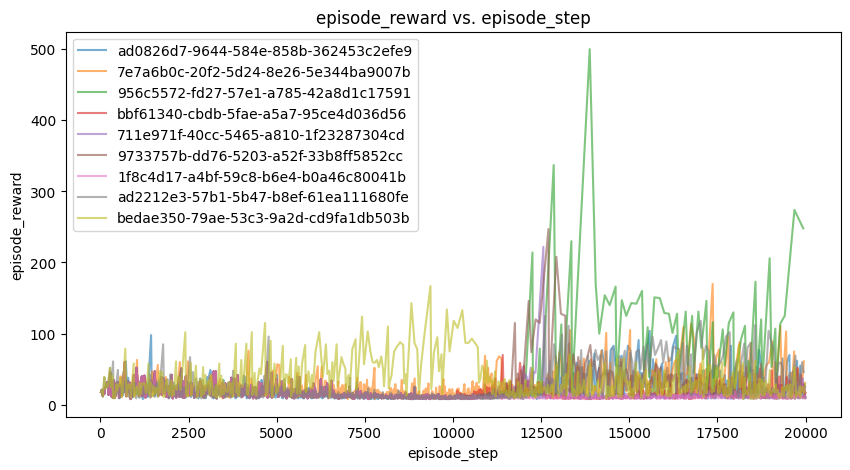

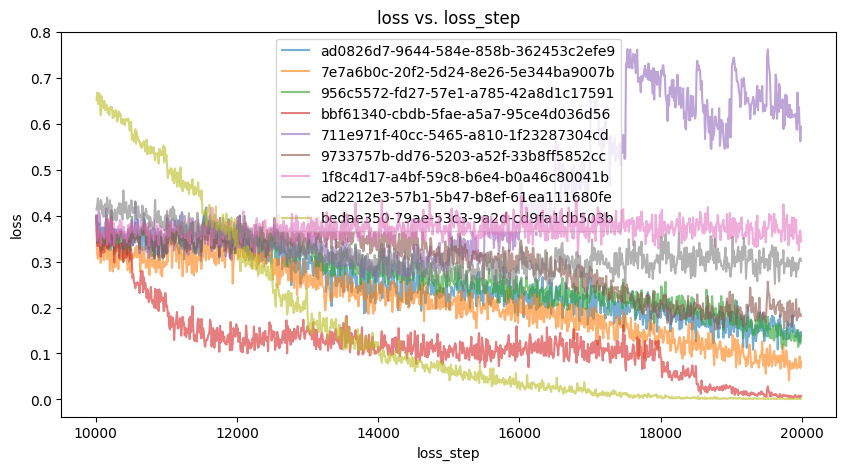

In [275]:
from qnrl.cli import PlotMatplotlib

# uuids = [
#     "711e971f-40cc-5465-a810-1f23287304cd",
#     "9733757b-dd76-5203-a52f-33b8ff5852cc",
#     "cf096b17-17ec-5e33-b855-00821ba8fb65",
#     "1e254db4-1568-5d28-92f6-c7abce40290a",
# ]

uuids = store.keys()

# Construct paths to all *potential* history files in store.
history_files = [Path(f"metrics/{uuid}.json") for uuid in uuids]
# Filter out files that don't exist.
history_files = list(filter(lambda path: path.exists(), history_files))

# Generate figures.
figs = [
    PlotMatplotlib(
        history=history_files,
        x="episode_step",
        y="episode_reward",
        figure_kwargs=dict(figsize=(10,5)),
        alpha=0.6,
    )(),
    PlotMatplotlib(
        history=history_files,
        x="loss_step",
        y="loss",
        figure_kwargs=dict(figsize=(10,5)),
        alpha=0.6,
    )(),
]

In [77]:
# Show the differences between all items of the configs.
# WARNING: This could run for a long time depending on how large the store is.

from deepdiff import DeepDiff
import itertools

def diff(d: dict):
    """Compute diff across a dictionary of configurations."""
    keys = list(d.keys())
    
    lines = []
    for key_src, key_dst in itertools.combinations(keys, 2):
        diff = DeepDiff(d[key_src], d[key_dst], ignore_order=True, exclude_paths=['metric_manager', 'checkpoint'])
        lines.append(f"{key_src} <-> {key_dst}")
        lines.extend(diff.pretty(prefix='\t').splitlines())
    return lines

# cfgs = {uuid: qnrl.algorithms.algorithm.Algorithm.from_dict(json.loads(store[uuid])) for uuid in uuids}
cfgs = {uuid: json.loads(store[uuid]) for uuid in uuids}
print('\n'.join(diff(cfgs)))

9733757b-dd76-5203-a52f-33b8ff5852cc <-> 1c6b6f3a-26b7-5c3b-8adf-416bdebcb935
	Value of root['model']['n_reuploads'] changed from 2 to 1.
	Value of root['model']['n_layers'] changed from 5 to 1.
	Value of root['optimizer'] changed from {'type': 'partition', 'transforms': {'key_circuit_weights': {'type': 'adam', 'learning_rate': 0.001, 'b1': 0.9, 'b2': 0.999, 'eps': 1e-08, 'eps_root': 0.0, 'mu_dtype': None, 'nesterov': False}, 'key_layer_project_input': {'type': 'adam', 'learning_rate': 0.01, 'b1': 0.9, 'b2': 0.999, 'eps': 1e-08, 'eps_root': 0.0, 'mu_dtype': None, 'nesterov': False}}, 'pytree': {'circ_weights': 'key_circuit_weights', 'layer_project_input': {'bias': 'key_layer_project_input', 'kernel': 'key_layer_project_input'}}} to {'type': 'adam', 'learning_rate': 0.001, 'b1': 0.9, 'b2': 0.999, 'eps': 1e-08, 'eps_root': 0.0, 'mu_dtype': None, 'nesterov': False}.
	Value of root['policy_type'] changed from "phased_stochastic_greedy" to "greedy".
	Value of root['target_type'] changed fro

In [23]:
# Keep a backup copy.
history_list_backup = history_list.copy()
history_dict_backup = history_dict.copy()

### Sandbox for density matrix

In [24]:
obs = env.reset()[0]

model.call_gen_action_dist(obs)

Array([[0.4, 0.6]], dtype=float64)

In [25]:
model = config.model

key = jax.random.PRNGKey(0)
# device_name = 'default.mixed'
device_name = 'default.qubit'
shots = None
# diff_method = "backprop"
diff_method = None
inputs = jax.random.normal(key=key, shape=model.circ_inputs_shape)
weights = model.circ_weights
probs_actions = jnp.ones(shape=(model.n_actions,))
n_actions = model.n_actions
d_actions = model.d_actions
d_returns = model.d_returns
n_layers = model.n_layers
U_atoms=model.U_atoms

# func = run_circuit_return_density_matrix
# func = qml.snapshots(func)
# func(
#     key=key,
#     device_name=device_name,
#     shots=shots,
#     diff_method=diff_method,
#     inputs=inputs,
#     weights=weights,
#     probs_actions=probs_actions,
#     n_actions=n_actions,
#     d_actions=d_actions,
#     d_returns=d_returns,
#     n_layers=n_layers,
# )

device = qml.device(name=device_name, shots=shots, seed=key)
qnode = qml.QNode(func=circuit_action_dist, device=device, interface="jax", diff_method=diff_method)
qnode = qml.snapshots(qnode)
snap = qnode(
    inputs=inputs,
    probs_actions=probs_actions,
    weights=weights,
    n_actions=n_actions,
    d_actions=d_actions,
    d_returns=d_returns,
    m_moment=m_moment,
    n_layers=n_layers,
    U_atoms=U_atoms,
)

In [26]:
snap['execution_results']

Array([0.26383394, 0.18804396], dtype=float64)

In [27]:
model = config.model

key = jax.random.PRNGKey(0)
device_name = 'default.mixed'
# device_name = 'default.qubit'
shots = None
diff_method = "backprop"
inputs = jax.random.normal(key=key, shape=model.circ_inputs_shape)
weights = model.circ_weights
probs_actions = jnp.ones(shape=(model.n_actions,))
n_actions = model.n_actions
d_actions = model.d_actions
d_returns = model.d_returns
n_layers = model.n_layers

# func = run_circuit_return_density_matrix
# func = qml.snapshots(func)
# func(
#     key=key,
#     device_name=device_name,
#     shots=shots,
#     diff_method=diff_method,
#     inputs=inputs,
#     weights=weights,
#     probs_actions=probs_actions,
#     n_actions=n_actions,
#     d_actions=d_actions,
#     d_returns=d_returns,
#     n_layers=n_layers,
# )

device = qml.device(name=device_name, shots=shots, seed=key)
qnode = qml.QNode(func=circuit_return_density_matrix, device=device, interface="jax", diff_method=diff_method)
qnode = qml.snapshots(qnode)
snap = qnode(
    inputs=inputs,
    probs_actions=probs_actions,
    weights=weights,
    n_actions=n_actions,
    d_actions=d_actions,
    d_returns=d_returns,
    n_layers=n_layers,
)

In [28]:
snap['after_action_prep'], jnp.trace(snap['after_action_prep'])

(Array([[0.5+0.j, 0. +0.j, 0. +0.j, ..., 0. +0.j, 0. +0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0. +0.j, ..., 0. +0.j, 0. +0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0. +0.j, ..., 0. +0.j, 0. +0.j, 0. +0.j],
        ...,
        [0. +0.j, 0. +0.j, 0. +0.j, ..., 0. +0.j, 0. +0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0. +0.j, ..., 0. +0.j, 0. +0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0. +0.j, ..., 0. +0.j, 0. +0.j, 0. +0.j]],      dtype=complex128),
 Array(1.+0.j, dtype=complex128))

In [29]:
snap['after_return_prep'], jnp.trace(snap['after_return_prep'])

(Array([[ 3.42025766e-02+2.85584719e-18j, -8.30393437e-03+6.25316742e-03j,
          1.26342460e-03+7.87705637e-03j, ...,
          2.30173100e-02-3.69486370e-03j,  2.21697288e-02+1.40621075e-03j,
         -9.14389438e-03+4.60769258e-03j],
        [-8.30393437e-03-6.25316742e-03j,  3.15933592e-03-5.61126567e-18j,
          1.13339874e-03-2.14343397e-03j, ...,
         -6.26382144e-03-3.31113028e-03j, -5.12542385e-03-4.39464282e-03j,
          3.06242927e-03+5.53067269e-04j],
        [ 1.26342460e-03-7.87705637e-03j,  1.13339874e-03+2.14343397e-03j,
          1.86080305e-03+4.58345881e-18j, ...,
         -7.02112041e-07-5.43750934e-03j,  1.14279642e-03-5.05387545e-03j,
          7.23408455e-04+2.27609880e-03j],
        ...,
        [ 2.30173100e-02+3.69486370e-03j, -6.26382144e-03+3.31113028e-03j,
         -7.02112041e-07+5.43750934e-03j, ...,
          1.58891122e-02-1.63923740e-18j,  1.47676524e-02+3.34130718e-03j,
         -6.65133068e-03+2.11303510e-03j],
        [ 2.21697288e-02-1.

In [30]:
snap['execution_results'], jnp.trace(snap['execution_results'])

(Array([[ 3.42025766e-02+2.85584719e-18j, -8.30393437e-03+6.25316742e-03j,
          1.26342460e-03+7.87705637e-03j, ...,
          2.30173100e-02-3.69486370e-03j,  2.21697288e-02+1.40621075e-03j,
         -9.14389438e-03+4.60769258e-03j],
        [-8.30393437e-03-6.25316742e-03j,  3.15933592e-03-5.61126567e-18j,
          1.13339874e-03-2.14343397e-03j, ...,
         -6.26382144e-03-3.31113028e-03j, -5.12542385e-03-4.39464282e-03j,
          3.06242927e-03+5.53067269e-04j],
        [ 1.26342460e-03-7.87705637e-03j,  1.13339874e-03+2.14343397e-03j,
          1.86080305e-03+4.58345881e-18j, ...,
         -7.02112041e-07-5.43750934e-03j,  1.14279642e-03-5.05387545e-03j,
          7.23408455e-04+2.27609880e-03j],
        ...,
        [ 2.30173100e-02+3.69486370e-03j, -6.26382144e-03+3.31113028e-03j,
         -7.02112041e-07+5.43750934e-03j, ...,
          1.58891122e-02-1.63923740e-18j,  1.47676524e-02+3.34130718e-03j,
         -6.65133068e-03+2.11303510e-03j],
        [ 2.21697288e-02-1.

### Eval

In [36]:
config.eval()

  0%|          | 16/20000 [00:00<01:36, 206.95step/s, episode_step=16, episode_reward=17, episode_length=17, episode_time=0.0776]


[{'pmfs': Array([0.38, 0.62], dtype=float64),
  'action': 0,
  'reward': 1.0,
  'observation': Array([-0.01706346, -0.00357923, -0.05234306,  0.00718461], dtype=float64),
  'next_observation': Array([-0.01713803, -0.08156427, -0.05063243,  0.12286247], dtype=float64),
  'done': False},
 {'pmfs': Array([0.18, 0.82], dtype=float64),
  'action': 1,
  'reward': 1.0,
  'observation': Array([-0.01713803, -0.08156427, -0.05063243,  0.12286247], dtype=float64),
  'next_observation': Array([-0.01883728, -0.00345554, -0.02137947,  0.00445559], dtype=float64),
  'done': False},
 {'pmfs': Array([0.35, 0.65], dtype=float64),
  'action': 1,
  'reward': 1.0,
  'observation': Array([-0.01883728, -0.00345554, -0.02137947,  0.00445559], dtype=float64),
  'next_observation': Array([-0.01890927,  0.07461888, -0.02031861, -0.11318284], dtype=float64),
  'done': False},
 {'pmfs': Array([0.62, 0.38], dtype=float64),
  'action': 0,
  'reward': 1.0,
  'observation': Array([-0.01890927,  0.07461888, -0.02031861

In [32]:
history_list[-10:]

[{'loss_step': 19940, 'loss': Array(0.40806095, dtype=float64)},
 {'loss_step': 19950, 'loss': Array(0.43582649, dtype=float64)},
 {'episode_step': 19951,
  'episode_reward': 15.0,
  'episode_length': 15,
  'episode_time': 1.591285,
  'episode_utcisotime': '2025-09-10T16:05:33.987255+00:00'},
 {'loss_step': 19960, 'loss': Array(0.42012679, dtype=float64)},
 {'episode_step': 19966,
  'episode_reward': 14.0,
  'episode_length': 14,
  'episode_time': 0.836886,
  'episode_utcisotime': '2025-09-10T16:05:34.831280+00:00'},
 {'loss_step': 19970, 'loss': Array(0.43615972, dtype=float64)},
 {'episode_step': 19980,
  'episode_reward': 13.0,
  'episode_length': 13,
  'episode_time': 0.832411,
  'episode_utcisotime': '2025-09-10T16:05:35.669928+00:00'},
 {'loss_step': 19980, 'loss': Array(0.43582306, dtype=float64)},
 {'loss_step': 19990, 'loss': Array(0.44816706, dtype=float64)},
 {'episode_step': 19993,
  'episode_reward': 12.0,
  'episode_length': 12,
  'episode_time': 0.819106,
  'episode_utci

In [33]:
def is_unitary(m: jnp.ndarray):
    return jnp.allclose(jnp.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: jnp.ndarray):
    return jnp.allclose(m, m.T.conj())

In [34]:
from qnrl.algorithms.qnrl_v2 import *

model_policy: QuantumNativeQNetworkSplit_v3 = config.model
graphdef, state = nnx.split(model_policy)
model_target = nnx.merge(graphdef, state)

env = config.env.make()
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).


# observation, _ = env.reset()

# Generate some random observations.
batch_size = 3
observations = jnp.array([env.reset()[0] for _ in range(batch_size)])
next_observations = jnp.array([env.reset()[0] for _ in range(batch_size)])

# # Ensure batched.
# observation = jnp.reshape(observation, (-1, model.din))

# Test creating rho.
target_action_pmfs = model_target.call_gen_action_dist(next_observations)
target_actions = jnp.argmax(target_action_pmfs, axis=-1) # (batch,)
target_actions_onehot = nnx.one_hot(target_actions, num_classes=model_target.n_actions) # PMF for greedy action.
target_return_pmfs = model_target.call_gen_return_dist_NEW(next_observations, target_actions_onehot) # (batch_size,n_atoms)
psi = jnp.sqrt(target_return_pmfs) # (batch,d_returns,) State vector representation of target return-atom PMFs.
rho = nnx.vmap(density_matrix)(psi) # (batch,2**d_returns,2**d_returns,) Density matrix (i.e., Hermitian core) representation of target return-atom. We need this to be batched, so also create a batched variant of `density_matrix` using `nnx.vmap`.

# Get output from policy model.
policy_action_pmfs = model_policy.call_gen_action_dist(observations) # (batch,n_actions,)


# print(f"{target_action_pmfs.shape = }")
# print(f"{target_actions.shape = }")
# print(f"{target_actions_onehot.shape = }")
# print(f"{target_return_pmfs.shape = }")
# print(f"{psi.shape = }")
# print(f"{rho.shape = }")
# print(f"{is_hermitian(rho) = }")
# print(f"{is_unitary(rho) = }")
print(f"{observations.shape = }")
# print(f"{policy_action_pmfs.shape = }")

model_policy.call_hermitian_loss(observations, policy_action_pmfs, rho)

# # Must project the observations into a space ingestible for the quantum circuit.
# circuit_inputs = model.layer_project_input(observation)
# circuit_inputs = jnp.reshape(circuit_inputs, (-1, *model.circ_inputs_shape,)) # (batch,d_returns,1,)
# device = qml.device('default.qubit', shots=None)
# qnode = qml.QNode(func=circuit_hermitian_loss, device=device, interface="jax", diff_method='backprop')
# qnode_vmap = nnx.vmap(
#     f=qnode,
#     in_axes=(0, 0, None, None, None, None, None, 0),
#     out_axes=0,
# )
# qnode_vmap(
#     inputs=circuit_inputs,
#     probs_actions=policy_action_pmfs,
#     weights=model.circ_weights,
#     n_actions=model.n_actions,
#     d_actions=model.d_actions,
#     d_returns=model.d_returns,
#     n_layers=model.n_layers,
#     rho=rho,
# )

# for t in range(500):
#     action_pmf = model.call_gen_action_dist(observation)
#     action = action_pmf.argmax().item()
    
#     return_pmf = model.call_gen_return_dist_NEW(observation, action_pmf).squeeze()
    
#     next_observation, reward, done, truncation, info = env.step(action)
    
    
#     # print(f"{observation = }")
#     # print(f"{action_pmf = }")
#     # print(f"{action = }")
#     # print(f"{return_pmf = }")
#     # print(f"{return_pmf.sum() = }")
#     # print()
    
#     # # Plot the returns PMF.
#     # plt.figure(figsize=(14,8))
#     # x = jnp.arange(len(return_pmf))
#     # plt.bar(x, return_pmf)
#     # plt.xticks(x, [f"{i:0{model.d_returns}b}"[::-1] + f" : z{i}" for i in range(model.n_returns)], rotation=90)
#     # plt.xlabel("State index (binary) : Return atom")
#     # plt.show()
    
#     observation = next_observation.copy()
    
#     if done:
#         break
# print(info)

ERROR:2025-09-10 12:05:45,014:jax._src.callback:95: jax.pure_callback failed
Traceback (most recent call last):
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/callback.py", line 93, in pure_callback_impl
    return tree_util.tree_map(np.asarray, callback(*args))
                                          ^^^^^^^^^^^^^^^
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/callback.py", line 71, in __call__
    return tree_util.tree_leaves(self.callback_func(*args, **kwargs))
                                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/pennylane/workflow/interfaces/jax_jit.py", line 168, in pure_callback_wrapper
    return _to_jax(execute_fn(new_tapes))
                   ^^^^^^^^^^^^^^^^^^^^^
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/pennylane/workflow/run.py", line 256, in inner_execute
    results = device.execu

XlaRuntimeError: INTERNAL: CpuCallback error calling callback: Traceback (most recent call last):
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/callback.py", line 782, in _wrapped_callback
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/callback.py", line 222, in _callback
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/callback.py", line 96, in pure_callback_impl
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/jax/_src/callback.py", line 71, in __call__
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/pennylane/workflow/interfaces/jax_jit.py", line 168, in pure_callback_wrapper
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/pennylane/workflow/run.py", line 256, in inner_execute
  File "/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/pennylane/devices/modifiers/simulator_tracking.py", line 28,

In [ ]:
# qnrl.algorithms.qnrl_v2.circuit_return_dist(None, None, None, None, None, None, None, 1, 5, None)

# Compare return PMF distributions

## QnRL

In [ ]:
# Load config from file.
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-13.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-12.py")
cfg_path = Path("./experiments/qnrl_CartPole-v1_config-11.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-10.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-9.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-8.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-7.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-6.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-5.py")
# cfg_path = Path("./experiments/qnrl_CartPole-v1_config-0.py")
module = qnrl.tools.load_python_module_from_filepath(cfg_path)
config = module.config

nnx.display(config)

In [ ]:
model: qnrl.modules.QuantumNativeQNetworkSplit = config.model
checkpoint_manager = config.checkpoint.make()
step_to_restore = checkpoint_manager.latest_step()
if step_to_restore is not None:
    model = qnrl.tools.restore_model_from_checkpointmanager(model, checkpoint_manager)
    print(f"Restored model from step: {step_to_restore}")

env = config.env.make()
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).


observation, _ = env.reset()

history = []
for t in range(500):
    action_pmf = model.call_gen_action_dist(observation)
    action = action_pmf.argmax().item()
    
    return_pmf = model.call_gen_return_dist_NEW(observation, action_pmf).squeeze()
    
    history.append({
        'step': t,
        'action_pmf': action_pmf.squeeze(),
        'action': action,
        'return_pmf': return_pmf,
        'observation': observation,
    })
    
    next_observation, reward, done, truncation, info = env.step(action)
    
    
    # print(f"{observation = }")
    # print(f"{action_pmf = }")
    # print(f"{action = }")
    # print(f"{return_pmf = }")
    # print(f"{return_pmf.sum() = }")
    # print()
    
    # # Plot the returns PMF.
    # plt.figure(figsize=(14,8))
    # x = jnp.arange(len(return_pmf))
    # plt.bar(x, return_pmf)
    # plt.xticks(x, [f"{i:0{model.d_returns}b}"[::-1] + f" : z{i}" for i in range(model.n_returns)], rotation=90)
    # plt.xlabel("State index (binary) : Return atom")
    # plt.show()
    
    observation = next_observation.copy()
    
    if done:
        break
print(info)

Restored model from step: 499990
{'episode': {'r': 14.0, 'l': 14, 't': 0.101854}}


/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/orbax/checkpoint/_src/serialization/type_handlers.py:1269: UserWarning: Sharding info not provided when restoring. Populating sharding info from sharding file. Please note restoration time will be slightly increased due to reading from file. Note also that this option is unsafe when restoring on a different topology than the checkpoint was saved with.
  warnings.warn(


0.04427185967699771
0.06268060061387029


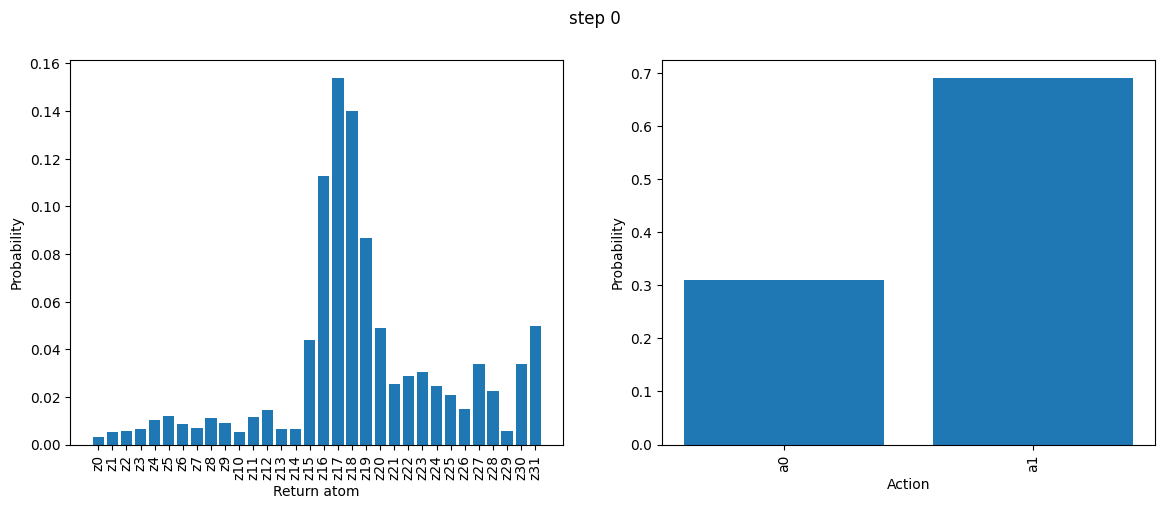

<Figure size 640x480 with 0 Axes>

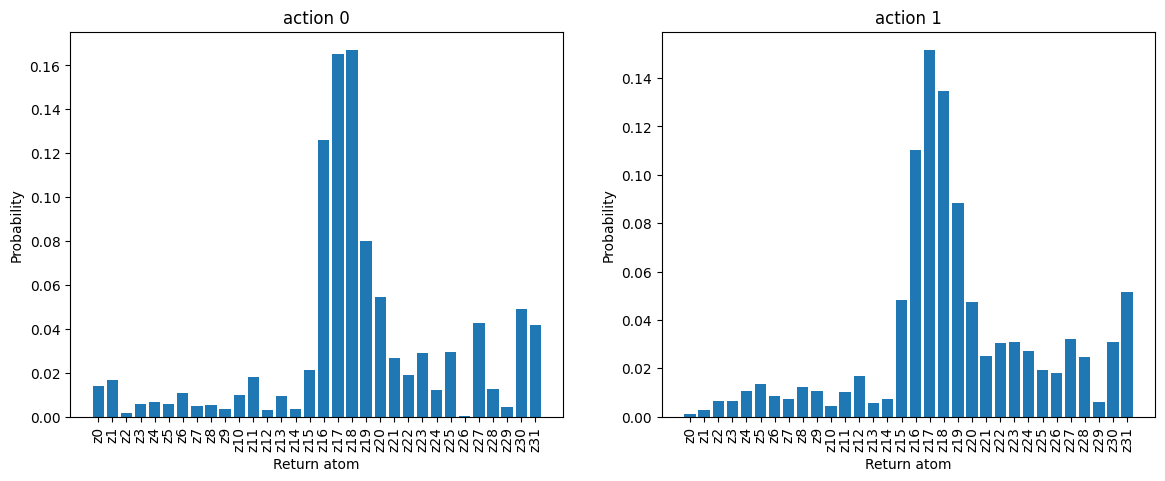

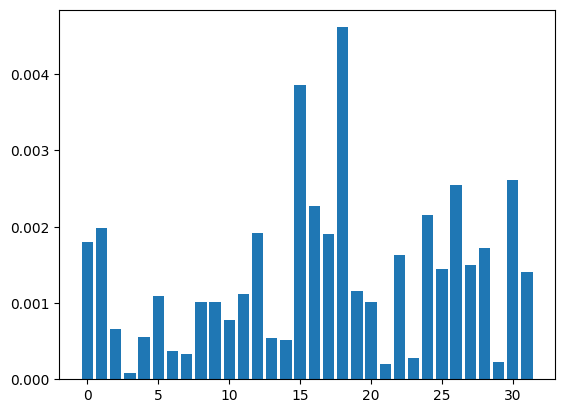

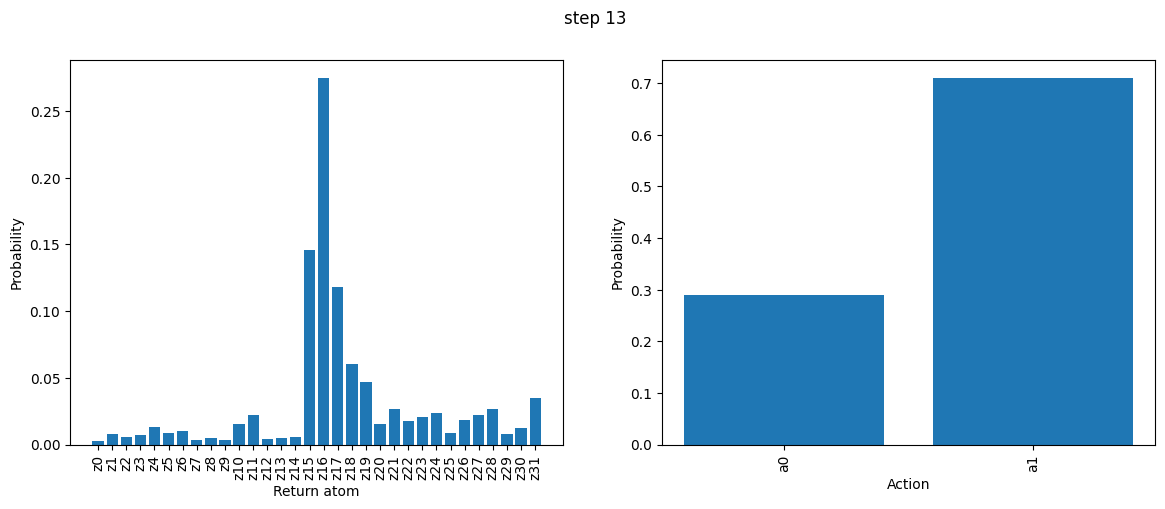

<Figure size 640x480 with 0 Axes>

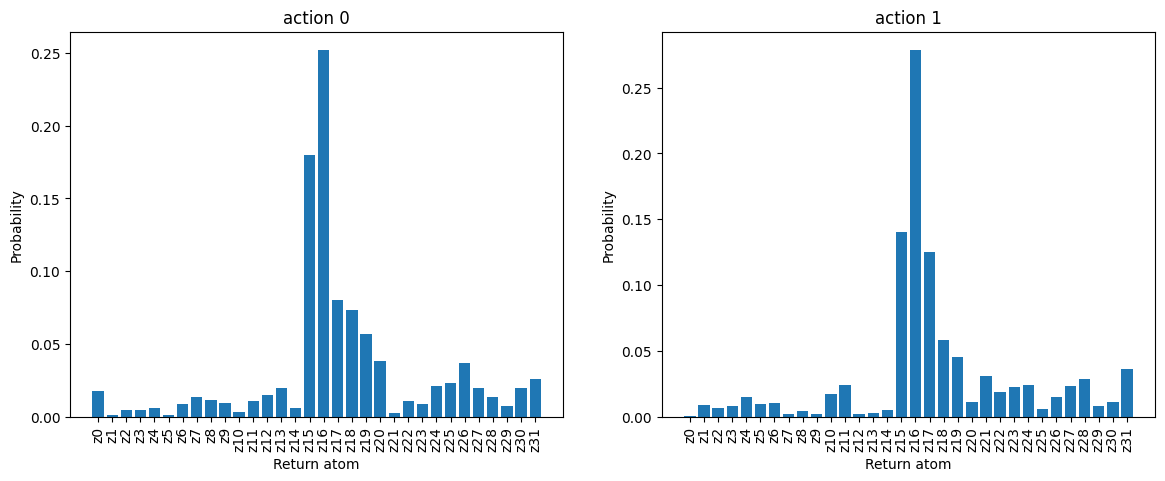

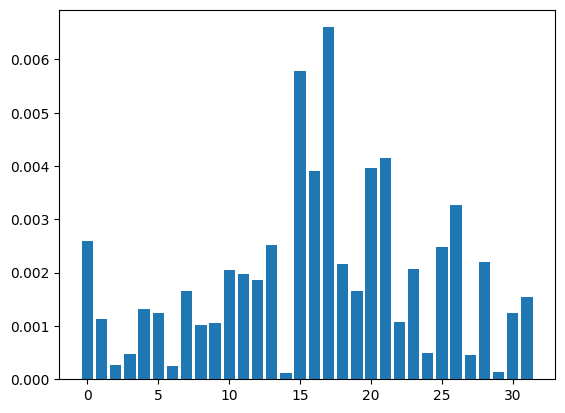

In [ ]:
# Plot the returns PMF.
# for t, d in enumerate(history[:5]):
for _, d in enumerate([history[0], history[-1]]):
    fig, axs = plt.subplots(1,2, figsize=(14,5))
    x = jnp.arange(d['return_pmf'].shape[-1])
    axs[0].bar(x, d['return_pmf'])
    axs[0].set_xticks(x, [f"z{i}" for i in range(len(x))], rotation=90)
    axs[0].set_xlabel("Return atom")
    axs[0].set_ylabel("Probability")
    x = jnp.arange(d['action_pmf'].shape[-1])
    axs[1].bar(x, d['action_pmf'])
    axs[1].set_xticks(x, [f"a{i}" for i in range(len(x))], rotation=90)
    axs[1].set_xlabel("Action")
    axs[1].set_ylabel("Probability")
    # fig.show()
    fig.suptitle(f"step {d['step']}")
    
    
    # Plot the return PMF for each action individually.
    n_returns = d['return_pmf'].shape[-1]
    x = jnp.arange(n_returns)
    n_actions = 2
    plt.figure()
    # d_action = int(jnp.ceil(jnp.sqrt(n_actions)))
    # fig, axs = plt.subplots(d_action, d_action)
    fig, axs = plt.subplots(1, 2, figsize=(14,5))
    axs = axs.flatten()
    individual_return_pmf = []
    for a in range(n_actions):
        actions_onehot = nnx.one_hot(a, num_classes=n_actions)
        return_pmf = model.call_gen_return_dist_NEW(d['observation'], actions_onehot[None,:]).squeeze()
        axs[a].bar(jnp.arange(n_returns), return_pmf)
        axs[a].set_xticks(x, [f"z{i}" for i in range(len(x))], rotation=90)
        axs[a].set_title(f"action {a}")
        axs[a].set_xlabel("Return atom")
        axs[a].set_ylabel("Probability")
        individual_return_pmf.append(return_pmf)
    individual_return_pmf = jnp.array(individual_return_pmf)


    weighted_return_pmf = (individual_return_pmf * d['action_pmf'][:,None]).sum(axis=0)
    plt.figure()
    # plt.bar(jnp.arange(n_returns), weighted_return_pmf)
    plt.bar(jnp.arange(n_returns), jnp.abs(weighted_return_pmf - d['return_pmf']))
    print(jnp.abs(weighted_return_pmf - d['return_pmf']).sum())

In [ ]:
nnx.display(model.U_atoms)

## C51 baseline

In [ ]:
cfg_path = Path("./experiments/c51_CartPole-v1_config-0.py")
module = qnrl.tools.load_python_module_from_filepath(cfg_path)
config = module.config

nnx.display(config)

In [ ]:
checkpoint_manager = config.checkpoint.make()
step_to_restore = checkpoint_manager.latest_step()
model: qnrl.modules.Sequential = config.model
if step_to_restore is not None:
    model = qnrl.tools.restore_model_from_checkpointmanager(model, checkpoint_manager)
    print(f"Restored model from step: {step_to_restore}")

atoms = jnp.linspace(start=config.z_min, stop=config.z_max, num=config.num_atoms)


env = config.env.make()
env = gym.wrappers.RecordEpisodeStatistics(env) # Track statistics for every episode.
env = gym.wrappers.Autoreset(env) # Automatically reset the environment (continuous training).


observation, _ = env.reset()


history = []
for t in range(500):
    return_pmfs = model(observation).squeeze()
    q_vals = jnp.sum(return_pmfs * atoms, axis=-1)
    action = jnp.argmax(q_vals, axis=-1).item()
    
    
    history.append({
        'step': t,
        'return_pmfs': return_pmfs,
        'q_vals': q_vals,
        'action': action,
    })
    
    next_observation, reward, done, truncation, info = env.step(action)
    # print(f"{observation = }")
    # print(f"{q_vals = }")
    # print(f"{q_vals - q_vals.min() = }")
    # print(f"{q_vals/q_vals.sum() = }")
    # print(f"{action = }")
    # print()
    
    observation = next_observation.copy()
    
    if done:
        break

print(info)

/Users/derieux/.pyenv/versions/qnrl/lib/python3.12/site-packages/orbax/checkpoint/_src/serialization/type_handlers.py:1269: UserWarning: Sharding info not provided when restoring. Populating sharding info from sharding file. Please note restoration time will be slightly increased due to reading from file. Note also that this option is unsafe when restoring on a different topology than the checkpoint was saved with.
  warnings.warn(


Restored model from step: 499990
{'episode': {'r': 500.0, 'l': 500, 't': 0.333513}}


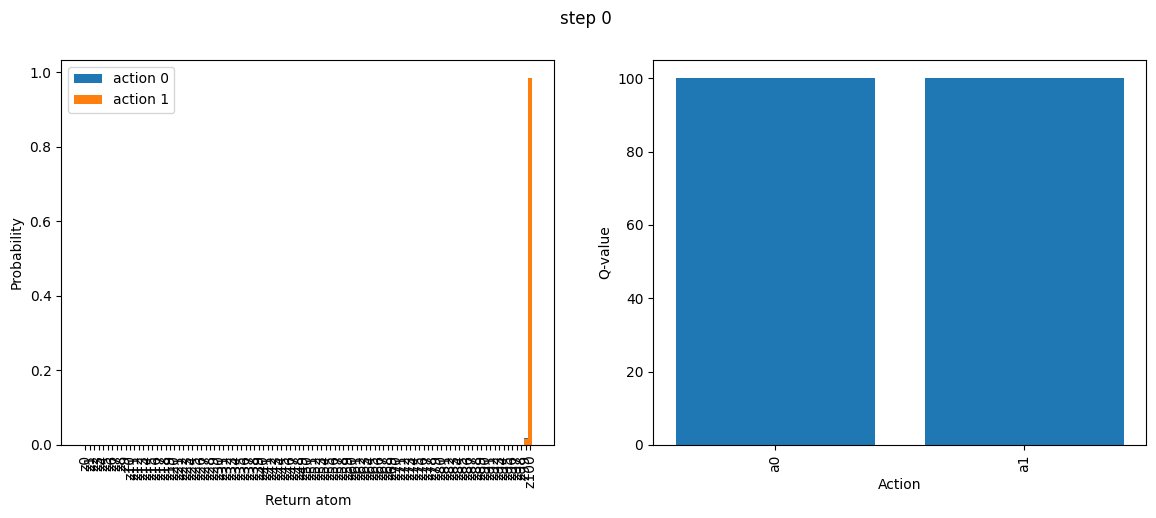

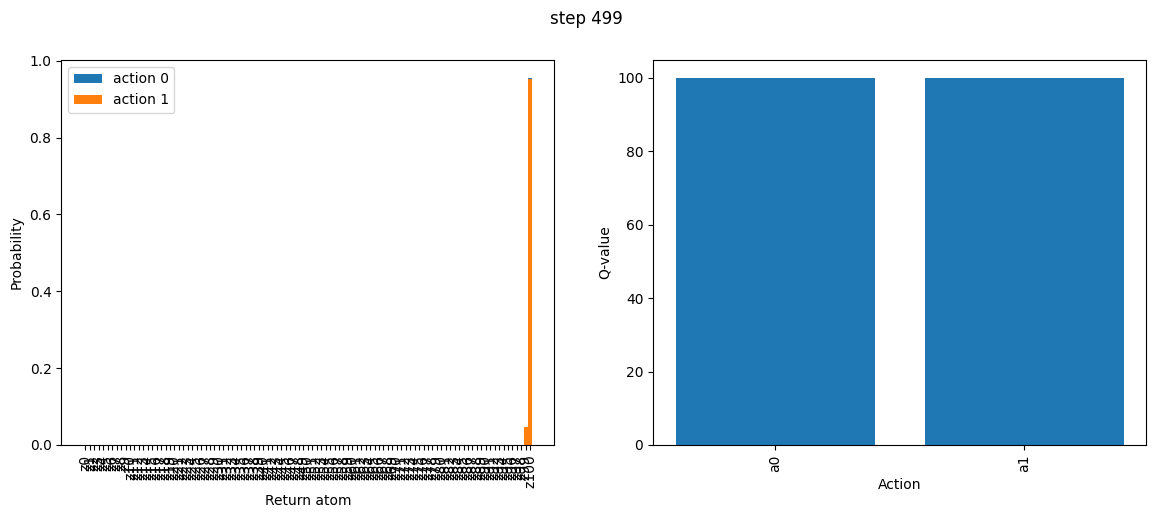

In [ ]:
# Plot the returns PMF.
# for t, d in enumerate(history[:5]):
for t, d in enumerate([history[0], history[-1]]):
    fig, axs = plt.subplots(1,2, figsize=(14,5))
    x = jnp.arange(d['return_pmfs'].shape[-1])
    for a in range(d['return_pmfs'].shape[0]):
        axs[0].bar(x, d['return_pmfs'][a], label=f"action {a}")
    axs[0].set_xticks(x, [f"z{i}" for i in range(len(x))], rotation=90)
    axs[0].set_xlabel("Return atom")
    axs[0].set_ylabel("Probability")
    axs[0].legend()
    x = jnp.arange(d['q_vals'].shape[-1])
    axs[1].bar(x, d['q_vals'])
    axs[1].set_xticks(x, [f"a{i}" for i in range(len(x))], rotation=90)
    axs[1].set_xlabel("Action")
    axs[1].set_ylabel("Q-value")
    # fig.show()
    fig.suptitle(f"step {d['step']}")